# Stock Market Data Analysis

## Part 1: Data Collection

In this part, we load the daily stock data of four major tech companies (Apple, Amazon, Google, Microsoft) from the S&P 500 dataset and combine them into a single DataFrame.

### 1.1 Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns

import glob

### 1.2 Check the Dataset

The dataset has one CSV file per company. Let's confirm that all files are available.

In [2]:
len(glob.glob("../data/individual_stocks_5yr/*.csv"))

505

### 1.3 Select Companies

We will analyse four companies: Apple (AAPL), Amazon (AMZN), Google (GOOG) and Microsoft (MSFT).

In [3]:
company_list = [
    '../data/individual_stocks_5yr/AAPL_data.csv',
    '../data/individual_stocks_5yr/AMZN_data.csv',
    '../data/individual_stocks_5yr/GOOG_data.csv',
    '../data/individual_stocks_5yr/MSFT_data.csv'
]

### 1.4 Load and Combine the Data

We read each company's CSV file and stack them into one DataFrame called `all_data`.

In [4]:
import warnings
from warnings import filterwarnings
filterwarnings("ignore")

all_data = pd.DataFrame()

for file in company_list:
    current_df = pd.read_csv(file)
    all_data = pd.concat([all_data , current_df] , ignore_index=True)

### 1.5 Inspect the Combined Data

Let's check the size of the data and preview the first rows.

In [5]:
all_data.shape

(4752, 7)

In [6]:
all_data.head(5)

,date,open,high,low,close,volume,Name
0,2013-02-08,67.7142,68.4014,66.8928,67.8542,158168416,AAPL
1,2013-02-11,68.0714,69.2771,67.6071,68.5614,129029425,AAPL
2,2013-02-12,68.5014,68.9114,66.8205,66.8428,151829363,AAPL
3,2013-02-13,66.7442,67.6628,66.1742,66.7156,118721995,AAPL
4,2013-02-14,66.3599,67.3771,66.2885,66.6556,88809154,AAPL


## Part 2: Data Preparation for Time Series Analysis

Stock data is a **time series**: every row is a price recorded on a specific date. Before analysing trends, we must make sure that dates are real date objects, there are no missing or duplicated values, and the rows are in chronological order for each company.

### 2.1 Check Columns and Data Types

In [7]:
all_data.columns

Index(['date', 'open', 'high', 'low', 'close', 'volume', 'Name'], dtype='str')

In [8]:
all_data.dtypes

date          str
open      float64
high      float64
low       float64
close     float64
volume      int64
Name          str
dtype: object

### 2.2 Convert the Date Column

The `date` column is currently stored as text. Converting it to the `datetime` type lets us sort chronologically, filter by period and calculate time-based metrics.

In [9]:
all_data["date"] = pd.to_datetime(all_data["date"])

In [10]:
all_data.dtypes

date      datetime64[us]
open             float64
high             float64
low              float64
close            float64
volume             int64
Name                 str
dtype: object

### 2.3 Check for Missing Values

In [11]:
all_data.isnull().sum()

date      0
open      0
high      0
low       0
close     0
volume    0
Name      0
dtype: int64

### 2.4 Check for Duplicate Rows

In [12]:
all_data.duplicated().sum()

np.int64(0)

### 2.5 Check for Invalid Trading Volume

A stock cannot have zero or negative trading volume on a trading day, so such rows would indicate bad data.

In [13]:
all_data[all_data["volume"] <= 0]

,date,open,high,low,close,volume,Name


### 2.6 Confirm the Companies in the Data

In [14]:
all_data["Name"].unique()

<StringArray>
['AAPL', 'AMZN', 'GOOG', 'MSFT']
Length: 4, dtype: str

### 2.7 Preview the Data

In [15]:
all_data.head(6)

,date,open,high,low,close,volume,Name
0,2013-02-08,67.7142,68.4014,66.8928,67.8542,158168416,AAPL
1,2013-02-11,68.0714,69.2771,67.6071,68.5614,129029425,AAPL
2,2013-02-12,68.5014,68.9114,66.8205,66.8428,151829363,AAPL
3,2013-02-13,66.7442,67.6628,66.1742,66.7156,118721995,AAPL
4,2013-02-14,66.3599,67.3771,66.2885,66.6556,88809154,AAPL
5,2013-02-15,66.9785,67.1656,65.7028,65.7371,97924631,AAPL


### 2.8 Sort the Data Chronologically

Time series calculations such as daily returns and moving averages depend on row order. We sort by company first, then by date, so each company's prices run in time order.

In [16]:
all_data = all_data.sort_values(["Name", "date"])

## Part 3: Which Is the Safest Stock to Invest In?

In finance, **risk** is commonly measured by **volatility**: how much a stock's daily returns fluctuate. We calculate each company's daily return, then compare the standard deviation of those returns. The stock with the **lowest** standard deviation has the most stable price.

### 3.1 Calculate Daily Returns

The daily return is the percentage change in the closing price compared to the previous day. We use `groupby('Name')` so that each company's returns are calculated separately and one company's prices never mix with another's.

In [17]:
all_data["daily_return"] = all_data.groupby('Name')['close'].pct_change()

### 3.2 Measure Risk (Volatility)

The standard deviation of daily returns shows how widely each stock's returns swing. A higher value means higher risk.

In [18]:
risk = all_data.groupby('Name')['daily_return'].std()
risk

Name
AAPL    0.014593
AMZN    0.018235
GOOG    0.014069
MSFT    0.014210
Name: daily_return, dtype: float64

### 3.3 Identify the Safest Stock

The safest stock is the one with the lowest volatility.

In [19]:
safest_stock = risk.idxmin()

safest_stock

'GOOG'

## Part 4: Which Stock Made the Most Money?

Volatility tells us how risky a stock is, but not how profitable it was. To measure profit, we use the **cumulative return**: the value at the end of the period of 1 dollar invested on the first day.

### 4.1 Inspect the Daily Returns

Let's look at the daily returns we calculated in Part 3.

In [20]:
all_data["daily_return"]

0            NaN
1       0.010422
2      -0.025067
3      -0.001903
4      -0.000899
          ...   
4747   -0.007894
4748   -0.026310
4749   -0.041185
4750    0.037841
4751   -0.018833
Name: daily_return, Length: 4752, dtype: float64

### 4.2 Calculate Cumulative Returns

Each day's growth factor is `1 + daily_return`. Multiplying these factors day after day (`cumprod`) shows how the investment compounds over time. We group by company so that each stock is calculated on its own, then take the last value of each group as the final result.

In [21]:
all_data["cumulative_return"] = (1 + all_data["daily_return"]).groupby(all_data["Name"]).cumprod()

final_returns = all_data.groupby('Name')["cumulative_return"].last()
final_returns

Name
AAPL    2.351218
AMZN    5.408589
GOOG    1.877628
MSFT    3.252632
Name: cumulative_return, dtype: float64

### 4.3 Find the Best-Performing Stock

The stock with the highest final cumulative return made the most money.

In [22]:
best_stock = final_returns.idxmax()
best_stock

'AMZN'

### 4.4 Visualize the Performance

A bar chart makes the comparison between the four stocks easy to see.

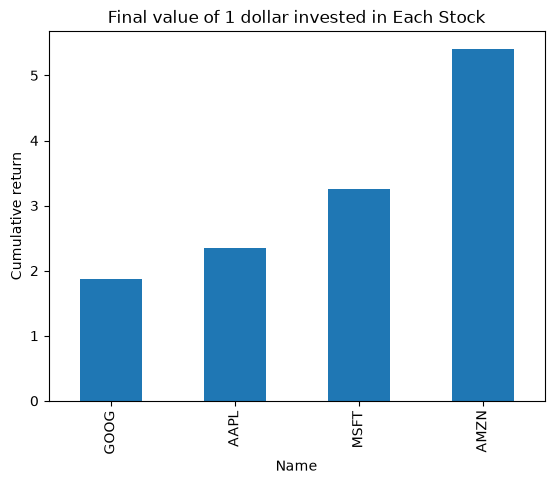

In [23]:
final_returns.sort_values().plot(kind="bar")
plt.title("Final value of 1 dollar invested in Each Stock")
plt.ylabel("Cumulative return")
plt.show()

## Part 5: 1 Million Investment Simulation

What would 1 million dollars invested in the best-performing stock have grown to? We use the cumulative return from Part 4 to simulate the value of the investment over time.

### 5.1 Select the Best-Performing Stock

In [24]:
best_stock = final_returns.idxmax()
best_stock

'AMZN'

### 5.2 Set the Investment Amount

In [25]:
investment = 1000000

### 5.3 Filter the Data for the Selected Stock

We keep only the rows that belong to the best-performing stock.

In [26]:
df_best = all_data[all_data["Name"] == best_stock]
df_best

,date,open,high,low,close,volume,Name,daily_return,cumulative_return
1259,2013-02-08,261.40,265.25,260.555,261.95,3879078,AMZN,NaN,NaN
1260,2013-02-11,263.20,263.25,256.600,257.21,3403403,AMZN,-0.018095,0.981905
1261,2013-02-12,259.19,260.16,257.000,258.70,2938660,AMZN,0.005793,0.987593
1262,2013-02-13,261.53,269.96,260.300,269.47,5292996,AMZN,0.041631,1.028708
1263,2013-02-14,267.37,270.65,265.400,269.24,3462780,AMZN,-0.000854,1.027830
...,...,...,...,...,...,...,...,...,...
2513,2018-02-01,1445.00,1459.88,1385.140,1390.00,9113808,AMZN,-0.041967,5.306356
2514,2018-02-02,1477.39,1498.00,1414.000,1429.95,11125722,AMZN,0.028741,5.458866
2515,2018-02-05,1402.62,1458.98,1320.720,1390.00,11494985,AMZN,-0.027938,5.306356
2516,2018-02-06,1361.46,1443.99,1351.790,1442.84,11066819,AMZN,0.038014,5.508074


### 5.4 Calculate the Investment Value Over Time

Multiplying the cumulative return by the starting investment gives the value of the portfolio on each day.

In [27]:
df_best["investment_value"] = df_best["cumulative_return"] * investment
df_best["investment_value"]

1259             NaN
1260    9.819049e+05
1261    9.875931e+05
1262    1.028708e+06
1263    1.027830e+06
            ...     
2513    5.306356e+06
2514    5.458866e+06
2515    5.306356e+06
2516    5.508074e+06
2517    5.408589e+06
Name: investment_value, Length: 1259, dtype: float64

### 5.5 Final Value of the Investment

In [28]:
df_best["investment_value"].tail(1).values[0]

np.float64(5408589.425462884)

### 5.6 Check the Columns

In [29]:
df_best.columns

Index(['date', 'open', 'high', 'low', 'close', 'volume', 'Name',
       'daily_return', 'cumulative_return', 'investment_value'],
      dtype='str')

### 5.7 Visualize the Investment Growth

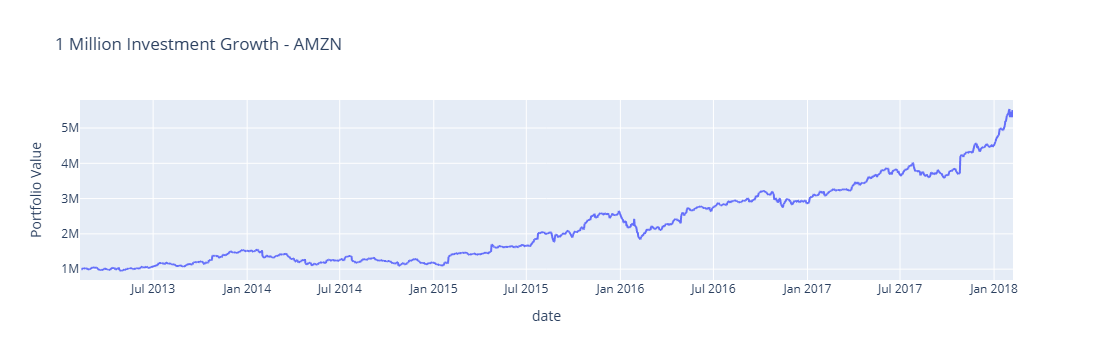

In [30]:
px.line(df_best ,
        x = "date" ,
        y = "investment_value" ,
        title = f"1 Million Investment Growth - {best_stock}" ,
        labels = {
            'investment_value' : "Portfolio Value"
        })

## Part 6: Crash Days

Volatility gives one average number for risk, but investors also care about the **worst-case days**. In this part, we find the five biggest single-day losses of each stock and compare them.

### 6.1 Worst Days of One Stock (AAPL)

We start with one company to understand the method. `nsmallest(5, 'daily_return')` returns the five rows with the lowest (most negative) daily returns.

In [31]:
all_data[all_data["Name"] == "AAPL"].nsmallest(5, 'daily_return')

,date,open,high,low,close,volume,Name,daily_return,cumulative_return
243,2014-01-28,72.6799,73.5714,71.7242,72.3571,266833581,AAPL,-0.079927,1.066361
746,2016-01-27,96.0400,96.6289,93.3400,93.4200,133369674,AAPL,-0.065707,1.376775
809,2016-04-27,96.0000,98.7100,95.6800,97.8200,114602142,AAPL,-0.062578,1.441620
638,2015-08-21,110.4300,111.9000,105.6450,105.7600,128275471,AAPL,-0.061163,1.558636
46,2013-04-17,60.0385,60.0857,56.8728,57.5428,236138966,AAPL,-0.054993,0.848036


### 6.2 Worst Days of Every Stock

We repeat the same search for each company. First we sort all rows by `daily_return` from the lowest (worst) to the highest. Then `groupby('Name').head(5)` keeps the first five rows of each company, which are its five worst days. Finally, we sort by company name for a tidy table.

In [35]:
worst_days = all_data.sort_values('daily_return').groupby('Name').head(5).sort_values(['Name', 'daily_return'])
worst_days

,date,open,high,low,close,volume,Name,daily_return,cumulative_return
243,2014-01-28,72.6799,73.5714,71.7242,72.3571,266833581,AAPL,-0.079927,1.066361
746,2016-01-27,96.0400,96.6289,93.3400,93.4200,133369674,AAPL,-0.065707,1.376775
809,2016-04-27,96.0000,98.7100,95.6800,97.8200,114602142,AAPL,-0.062578,1.441620
638,2015-08-21,110.4300,111.9000,105.6450,105.7600,128275471,AAPL,-0.061163,1.558636
46,2013-04-17,60.0385,60.0857,56.8728,57.5428,236138966,AAPL,-0.054993,0.848036
1505,2014-01-31,371.7600,375.4500,357.7600,358.6900,16181519,AMZN,-0.109972,1.369307
1563,2014-04-25,316.2500,316.4900,302.7100,303.8300,16186737,AMZN,-0.098828,1.159878
1626,2014-07-25,317.3000,324.8700,314.7600,324.0100,17855141,AMZN,-0.096484,1.236915
1690,2014-10-24,284.4000,293.8100,284.0000,287.0600,19805911,AMZN,-0.083403,1.095858
2007,2016-01-29,571.9800,593.0000,570.0000,587.0000,14677550,AMZN,-0.076100,2.240886


### 6.3 Check the Columns

In [33]:
worst_days.columns

Index(['date', 'open', 'high', 'low', 'close', 'volume', 'daily_return',
       'cumulative_return'],
      dtype='str')

### 6.4 Focus on the Key Columns

We only need the company name, the date and the return to describe a crash day.

In [36]:
worst_days[["Name", "date", "daily_return"]]

,Name,date,daily_return
243,AAPL,2014-01-28,-0.079927
746,AAPL,2016-01-27,-0.065707
809,AAPL,2016-04-27,-0.062578
638,AAPL,2015-08-21,-0.061163
46,AAPL,2013-04-17,-0.054993
1505,AMZN,2014-01-31,-0.109972
1563,AMZN,2014-04-25,-0.098828
1626,AMZN,2014-07-25,-0.096484
1690,AMZN,2014-10-24,-0.083403
2007,AMZN,2016-01-29,-0.076100


### 6.5 Check the Data Types

The `date` column must be a datetime type, because we will format it into text in a later step.

In [37]:
worst_days.dtypes

date                 datetime64[us]
open                        float64
high                        float64
low                         float64
close                       float64
volume                        int64
Name                            str
daily_return                float64
cumulative_return           float64
dtype: object

### 6.6 First Chart: Crash Days by Date

Let's plot the losses with the date on the x-axis.

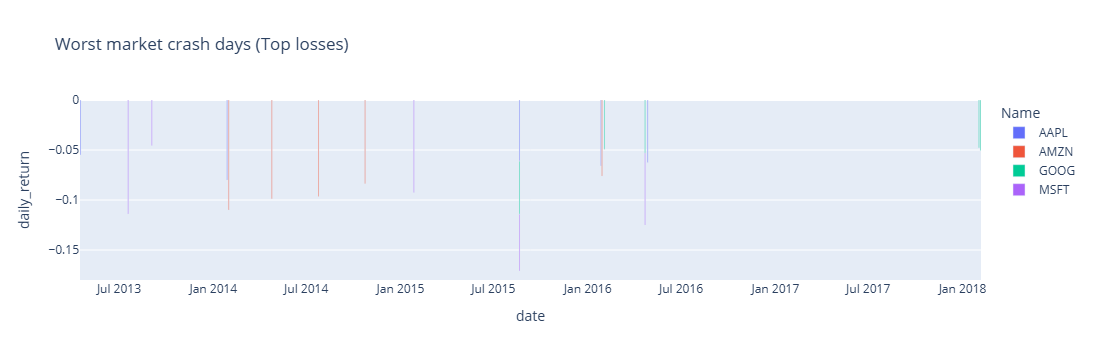

In [38]:
fig = px.bar(
    worst_days,
    x="date",
    y="daily_return",
    color="Name",
    title="Worst market crash days (Top losses)",
)

fig.show()

### 6.7 Create a Readable Label

The first chart has a problem: the crash dates are scattered across five years, so the x-axis is a long timeline and the bars become very thin. Instead, we create a text label combining the company and the date (for example `AAPL | 2015-08-24`) and use one bar per crash day.

In [39]:
worst_days["crash_label"] = worst_days["Name"] + " | " + worst_days["date"].dt.strftime("%Y-%m-%d")

worst_days

,date,open,high,low,close,volume,Name,daily_return,cumulative_return,crash_label
243,2014-01-28,72.6799,73.5714,71.7242,72.3571,266833581,AAPL,-0.079927,1.066361,AAPL | 2014-01-28
746,2016-01-27,96.0400,96.6289,93.3400,93.4200,133369674,AAPL,-0.065707,1.376775,AAPL | 2016-01-27
809,2016-04-27,96.0000,98.7100,95.6800,97.8200,114602142,AAPL,-0.062578,1.441620,AAPL | 2016-04-27
638,2015-08-21,110.4300,111.9000,105.6450,105.7600,128275471,AAPL,-0.061163,1.558636,AAPL | 2015-08-21
46,2013-04-17,60.0385,60.0857,56.8728,57.5428,236138966,AAPL,-0.054993,0.848036,AAPL | 2013-04-17
1505,2014-01-31,371.7600,375.4500,357.7600,358.6900,16181519,AMZN,-0.109972,1.369307,AMZN | 2014-01-31
1563,2014-04-25,316.2500,316.4900,302.7100,303.8300,16186737,AMZN,-0.098828,1.159878,AMZN | 2014-04-25
1626,2014-07-25,317.3000,324.8700,314.7600,324.0100,17855141,AMZN,-0.096484,1.236915,AMZN | 2014-07-25
1690,2014-10-24,284.4000,293.8100,284.0000,287.0600,19805911,AMZN,-0.083403,1.095858,AMZN | 2014-10-24
2007,2016-01-29,571.9800,593.0000,570.0000,587.0000,14677550,AMZN,-0.076100,2.240886,AMZN | 2016-01-29


### 6.8 Improved Chart: One Bar per Crash Day

Each bar is now one crash day, colored by company. The horizontal line at zero marks the baseline, so every bar points downward as a loss.

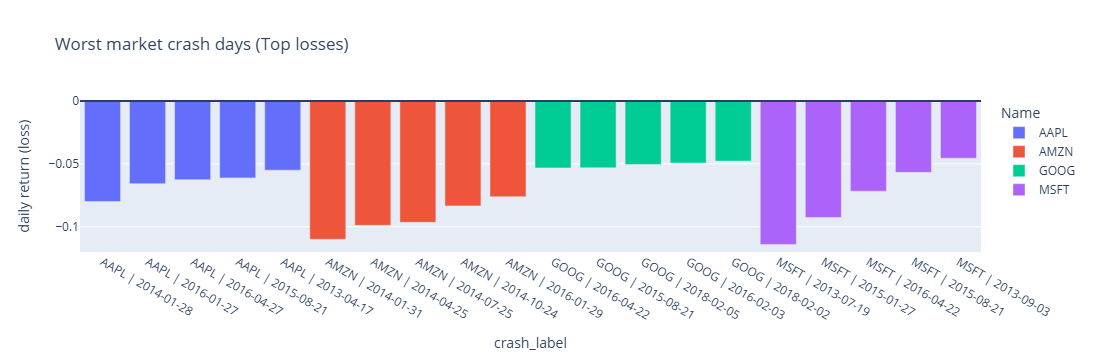

In [41]:
fig = px.bar(
    worst_days,
    x="crash_label",
    y="daily_return",
    color="Name",
    title="Worst market crash days (Top losses)",
    labels={"daily_return": "daily return (loss)"},
)

fig.add_hline(y=0)
fig.show()

## Part 7: Moving Average (Trend Analysis)

Daily stock prices move up and down constantly, which makes the overall trend hard to see. A **moving average** smooths these fluctuations by averaging the closing price over the last N days. We calculate a 20-day (short-term) and a 50-day (medium-term) moving average for each stock.

### 7.1 Inspect the Closing Prices

The closing price is the base for our moving averages.

In [42]:
all_data["close"]

0       67.8542
1       68.5614
2       66.8428
3       66.7156
4       66.6556
         ...   
4747    94.2600
4748    91.7800
4749    88.0000
4750    91.3300
4751    89.6100
Name: close, Length: 4752, dtype: float64

### 7.2 Calculate the 20-Day Moving Average

`rolling(20).mean()` averages each day's closing price with the previous 19 days. We use `groupby('Name')` so that one company's prices never mix into another company's average.

In [43]:
all_data["MA20"] = all_data.groupby('Name')["close"].transform(lambda x : x.rolling(20).mean())

### 7.3 Calculate the 50-Day Moving Average

The same method with a longer window. A longer window reacts more slowly to price changes, so it shows the longer-term trend.

In [44]:
all_data["MA50"] = all_data.groupby('Name')["close"].transform(lambda x : x.rolling(50).mean())

### 7.4 Preview the New Columns

In [45]:
all_data.head(5)

,date,open,high,low,close,volume,Name,daily_return,cumulative_return,MA20,MA50
0,2013-02-08,67.7142,68.4014,66.8928,67.8542,158168416,AAPL,NaN,NaN,NaN,NaN
1,2013-02-11,68.0714,69.2771,67.6071,68.5614,129029425,AAPL,0.010422,1.010422,NaN,NaN
2,2013-02-12,68.5014,68.9114,66.8205,66.8428,151829363,AAPL,-0.025067,0.985095,NaN,NaN
3,2013-02-13,66.7442,67.6628,66.1742,66.7156,118721995,AAPL,-0.001903,0.983220,NaN,NaN
4,2013-02-14,66.3599,67.3771,66.2885,66.6556,88809154,AAPL,-0.000899,0.982336,NaN,NaN


### 7.5 Select One Stock for the Trend Chart

We take Apple (AAPL) as an example to keep the chart readable.

In [46]:
df_stock = all_data[all_data["Name"] == "AAPL"]

In [47]:
df_stock.columns

Index(['date', 'open', 'high', 'low', 'close', 'volume', 'Name',
       'daily_return', 'cumulative_return', 'MA20', 'MA50'],
      dtype='str')

### 7.6 Plot the Price with Its Moving Averages

The chart shows the daily closing price together with the 20-day and 50-day moving averages.

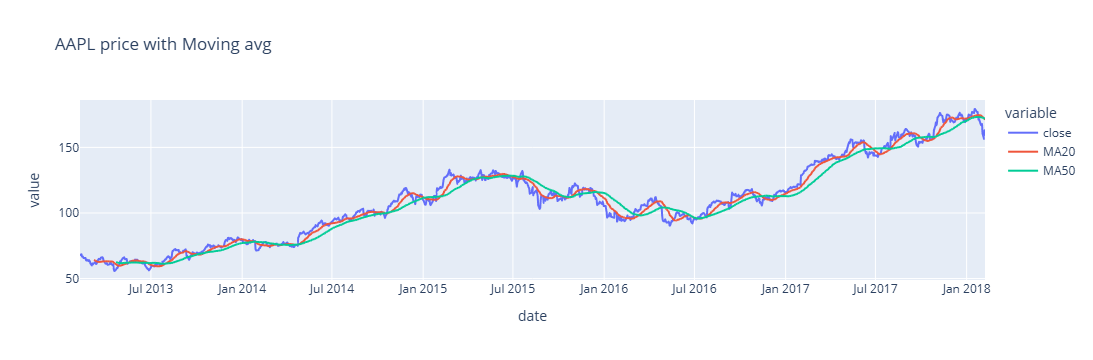

In [48]:
px.line(df_stock ,
        x = "date" ,
        y = ['close' , 'MA20', 'MA50'] ,
        title = "AAPL price with Moving avg")

## Part 8: Best Month to Invest in Each Stock

Do stocks perform better in certain months of the year? To find out, we group the daily returns by calendar month and compare the **average daily return** of each month for every stock. This kind of pattern is called **seasonality**.

### 8.1 Extract the Month Name

`dt.month_name()` converts each date into the name of its month (for example `2015-08-24` becomes `August`). This only works because we converted the `date` column to a datetime type in Part 2.

In [49]:
all_data["month_name"] = all_data["date"].dt.month_name()

### 8.2 Calculate the Average Daily Return per Month

We group by company and month, then take the mean of the daily returns. `reset_index()` turns the grouped result back into a regular table so that it can be plotted.

In [50]:
monthly_returns = all_data.groupby(["Name", "month_name"])["daily_return"].mean().reset_index()

### 8.3 Check the Columns

In [51]:
monthly_returns.columns

Index(['Name', 'month_name', 'daily_return'], dtype='str')

### 8.4 Visualize Average Returns by Month

A grouped bar chart places the four stocks side by side for every month, making it easy to compare them.

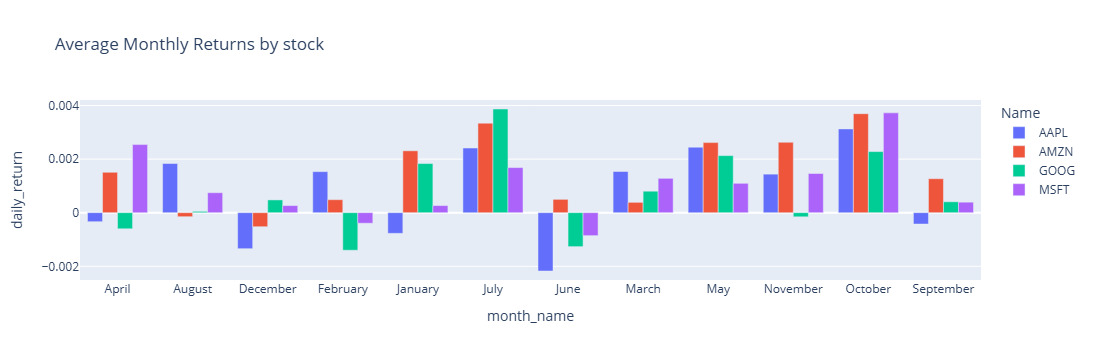

In [53]:
px.bar(monthly_returns,
       x = "month_name",
       y = "daily_return",
       color = "Name",
       barmode= "group",
       title = "Average Monthly Returns by stock")